<a href="https://colab.research.google.com/github/nhi0308-prog/FallDetection-TinyML-ESP32/blob/main/notebooks/train_1dcnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


1. Runtime → Change runtime type → T4 GPU nếu có.
2. Chạy cell cài thư viện.
3. Ở bảng Tệp bên trái Colab, bấm tải lên, chọn sensor_data_new_2.zip và label_data_new_2.zip. Đợi cả hai tải xong. Không giải nén trên máy.
4. Chạy cell đọc ZIP và các cell còn lại theo thứ tự.
5. Tải mô hình/kết quả và notebook về trước khi kết thúc phiên Colab.

Quy tắc baseline: Normal từ các bản ghi hoạt động thường; Fall là cửa sổ giao với đoạn onset..impact trong bản ghi ngã. Phần ngoài đoạn này của bản ghi ngã được bỏ, không gán nhãn tùy tiện. Đây là đánh giá cấp cửa sổ được chọn, chưa phải cảnh báo trước va chạm hoặc phát hiện trên dòng dữ liệu liên tục. Không bảo đảm F1 ≥ 0,90. Cần đánh giá báo động giả/giờ và độ trễ riêng trước khi triển khai.

Nguồn mô tả dữ liệu: https://sites.google.com/view/kfalldataset

In [1]:
%pip -q install numpy pandas scipy scikit-learn matplotlib openpyxl tqdm
import json, random, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import resample_poly
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import tensorflow as tf
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__, 'GPU', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 GPU [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [5]:
# Upload hai ZIP bằng bảng Tệp bên trái
import re, zipfile
from tqdm.auto import tqdm
SENSOR_ZIP = Path('/content/sensor_data_new_2.zip')
LABEL_ZIP = Path('/content/label_data_new_2.zip')
OUT = Path('/content/results')
OUT.mkdir(parents=True, exist_ok=True)
for p in (SENSOR_ZIP, LABEL_ZIP):
    assert p.is_file(), f'Chưa có {p.name}. Upload hoặc sửa đường dẫn nếu tên khác.'
ORIGINAL_FS, TARGET_FS = 100, 50
WINDOW, STEP = 100, 50
COLS = ['AccX','AccY','AccZ','GyrX','GyrY','GyrZ']
FALL_TASKS = set(range(20,35))
NORMAL_TASKS = set(range(1,20)) | {35,36}

# Task code chỉ có ở dòng đầu mỗi nhóm: forward-fill trước khi ghép trial.
annotations = {}
label_subjects = set()
with zipfile.ZipFile(LABEL_ZIP) as z:
    for name in sorted(z.namelist()):
        match = re.fullmatch(r'SA(\d+)_label\.xlsx', Path(name).name, flags=re.I)
        if not match:
            continue
        subject = int(match.group(1)); label_subjects.add(subject)
        with z.open(name) as f:
            table = pd.read_excel(f, engine='openpyxl')
        table.columns = [str(c).strip() for c in table.columns]
        required = ['Task Code (Task ID)','Trial ID','Fall_onset_frame','Fall_impact_frame']
        assert set(required).issubset(table.columns), f'Thiếu cột: {name}'
        codes = table['Task Code (Task ID)'].replace(r'^\s*$',np.nan,regex=True).ffill()
        task_ids = codes.astype(str).str.extract(r'\((\d+)\)',expand=False)
        assert task_ids.notna().all(), f'Task code không hợp lệ: {name}'
        assert set(task_ids.astype(int))==FALL_TASKS, f'Task ngã khác dự kiến: {name}'
        for pos, row in table.iterrows():
            nums = [float(row[c]) for c in required[1:]]
            assert all(np.isfinite(v) and v.is_integer() for v in nums), f'Nhãn không nguyên: {name}, dòng {pos}'
            trial,onset,impact = map(int,nums)
            assert trial>=1 and 1<=onset<=impact
            key=(subject,int(task_ids.loc[pos]),trial)
            assert key not in annotations, f'Nhãn trùng: {key}'
            annotations[key]=(onset,impact)
assert annotations, 'Không tìm thấy nhãn Excel'
print('Đọc được',len(annotations),'nhãn;',len(label_subjects),'người')

Đọc được 2346 nhãn; 32 người


In [6]:
# Ghép theo (subject, task, trial), không ghép theo thứ tự file.
# Nhãn frame được tra trực tiếp bằng FrameCounter, không giả định số dòng.
records = []
with zipfile.ZipFile(SENSOR_ZIP) as z:
    for name in sorted(z.namelist()):
        if not name.lower().endswith('.csv'):
            continue
        match = re.fullmatch(r'S(\d+)T(\d+)R(\d+)\.csv',Path(name).name,flags=re.I)
        assert match, f'Tên CSV không nhận dạng: {name}'
        key=tuple(map(int,match.groups()))
        records.append((name,key))
assert records, 'Không tìm thấy CSV'
keys=[key for _,key in records]
assert len(keys)==len(set(keys)), 'CSV trùng người/task/trial'
assert all(k[1] in FALL_TASKS|NORMAL_TASKS for k in keys)
missing=[k for k in keys if k[1] in FALL_TASKS and k not in annotations]
extra=[k for k in annotations if k not in set(keys)]
assert not missing and not extra, f'Nhãn/CSV lệch: thiếu {missing[:10]}, dư {extra[:10]}'
assert {k[0] for k in keys}==label_subjects

from scipy.signal import resample_poly
windows, labels, subjects, sources, starts = [],[],[],[],[]
audit=[]
with zipfile.ZipFile(SENSOR_ZIP) as z:
    for name,(subject,task,trial) in tqdm(records,desc='Tiền xử lý CSV'):
        with z.open(name) as f:
            df=pd.read_csv(f)
        assert set(COLS+['FrameCounter','TimeStamp(s)']).issubset(df.columns), f'Thiếu cột: {name}'
        a=df[COLS].to_numpy(dtype=np.float32)
        frames=df['FrameCounter'].to_numpy(dtype=float)
        times=df['TimeStamp(s)'].to_numpy(dtype=float)
        assert np.isfinite(a).all() and np.isfinite(frames).all() and np.isfinite(times).all(), f'NaN/Inf: {name}'
        assert len(a)>=200 and np.all(np.diff(frames)==1), f'CSV ngắn/mất frame: {name}'
        assert np.all(np.diff(times)>0) and np.isclose(np.median(np.diff(times)),1/ORIGINAL_FS,atol=1e-4), f'Tần số không phải 100Hz: {name}'
        fall = task in FALL_TASKS
        onset=impact=None
        if fall:
            onset,impact=annotations[(subject,task,trial)]
            onset_rows=np.flatnonzero(frames==onset); impact_rows=np.flatnonzero(frames==impact)
            assert len(onset_rows)==len(impact_rows)==1, f'Nhãn frame ngoài CSV: {name}'
            t0=onset_rows[0]/ORIGINAL_FS
            t1=(impact_rows[0]+1)/ORIGINAL_FS
        a=resample_poly(a,1,2,axis=0).astype(np.float32)
        n=0
        for start in range(0,len(a)-WINDOW+1,STEP):
            if fall and not (start/TARGET_FS<t1 and (start+WINDOW)/TARGET_FS>t0):
                continue
            windows.append(a[start:start+WINDOW]); labels.append(int(fall))
            subjects.append(f'SA{subject:02d}'); sources.append(name); starts.append(start); n+=1
        assert n>0, f'Không có cửa sổ: {name}'
        audit.append({'path':name,'subject':subject,'task':task,'trial':trial,'label':int(fall),
                      'onset_frame':onset,'impact_frame':impact,'windows':n})
X=np.stack(windows); del windows
y=np.array(labels,dtype=np.int32); groups=np.array(subjects)
sources=np.array(sources); source_files=sources
np.savez_compressed('/content/kfall_labeled.npz',X_data=X,y_data=y,subject_ids=groups,
                    source_files=sources,window_start_50hz=np.array(starts))
pd.DataFrame(audit).to_csv(OUT/'preprocessing_audit.csv',index=False)
print('X:',X.shape,'Normal/Fall:',np.bincount(y,minlength=2),'Số người:',len(set(groups)))
print('Đã tạo /content/kfall_labeled.npz — không cần số cửa sổ bằng NPZ cũ vì đã đổi quy tắc giữ cửa sổ.')

Tiền xử lý CSV:   0%|          | 0/5075 [00:00<?, ?it/s]

X: (25029, 100, 6) Normal/Fall: [18648  6381] Số người: 32
Đã tạo /content/kfall_labeled.npz — không cần số cửa sổ bằng NPZ cũ vì đã đổi quy tắc giữ cửa sổ.


In [7]:
# Tải dữ liệu đã xử lý về máy trước khi train
# Đây là cửa sổ IMU chưa chuẩn hóa, có nhãn và mã người khớp từng cửa sổ.
# Chuẩn hóa được fit riêng trên train ở cell tiếp theo để tránh rò rỉ dữ liệu.
from google.colab import files
DATASET_PATH = Path('/content/kfall_labeled.npz')
assert DATASET_PATH.is_file(), 'Chạy xong cell tiền xử lý phía trên trước'
with np.load(DATASET_PATH, allow_pickle=False) as saved:
    for key in saved.files:
        print(key, saved[key].shape, saved[key].dtype)
    assert len(saved['X_data']) == len(saved['y_data']) == len(saved['subject_ids'])
print('Đang tải kfall_labeled.npz về máy. Nếu trình duyệt hỏi, hãy cho phép tải xuống.')
files.download(str(DATASET_PATH))

X_data (25029, 100, 6) float32
y_data (25029,) int32
subject_ids (25029,) <U4
source_files (25029,) <U18
window_start_50hz (25029,) int64
Đang tải kfall_labeled.npz về máy. Nếu trình duyệt hỏi, hãy cho phép tải xuống.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
# Chia theo người, không chia ngẫu nhiên các cửa sổ chồng lấn.
assert len(set(groups))>=5, 'Cần ít nhất 5 người cho cách chia này'
trval, test = next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(X,y,groups))
a,b = next(GroupShuffleSplit(n_splits=1,test_size=.25,random_state=SEED).split(X[trval],y[trval],groups[trval]))
train,val = trval[a],trval[b]
assert not (set(groups[train])&set(groups[val]) or set(groups[train])&set(groups[test]) or set(groups[val])&set(groups[test]))
split = pd.DataFrame({'path':sources,'subject':groups,'label':y,'split':''})
for name,ix in [('train',train),('validation',val),('test',test)]:
    assert set(np.unique(y[ix]))=={0,1}, f'{name} thiếu lớp; xem lại phân bố nhãn/người'
    print(name,len(ix),'windows',sorted(set(groups[ix])),np.bincount(y[ix],minlength=2))
    split.loc[ix,'split']=name
split.drop_duplicates().to_csv(OUT/'split_manifest.csv',index=False)
# Chỉ fit chuẩn hóa trên train
mean = X[train].mean(axis=(0,1),keepdims=True)
std = np.maximum(X[train].std(axis=(0,1),keepdims=True),1e-6)
X_train,X_val,X_test = [(X[ix]-mean)/std for ix in (train,val,test)]
np.savez(OUT/'normalization.npz',mean=mean,std=std)

train 14159 windows [np.str_('SA07'), np.str_('SA08'), np.str_('SA09'), np.str_('SA10'), np.str_('SA11'), np.str_('SA12'), np.str_('SA13'), np.str_('SA18'), np.str_('SA20'), np.str_('SA24'), np.str_('SA25'), np.str_('SA27'), np.str_('SA28'), np.str_('SA29'), np.str_('SA31'), np.str_('SA32'), np.str_('SA33'), np.str_('SA38')] [10591  3568]
validation 5640 windows [np.str_('SA06'), np.str_('SA16'), np.str_('SA17'), np.str_('SA19'), np.str_('SA22'), np.str_('SA26'), np.str_('SA35')] [4239 1401]
test 5230 windows [np.str_('SA14'), np.str_('SA15'), np.str_('SA21'), np.str_('SA23'), np.str_('SA30'), np.str_('SA36'), np.str_('SA37')] [3818 1412]


In [9]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(WINDOW,6)),
    tf.keras.layers.Conv1D(32,5,padding='same',activation='relu'),
    tf.keras.layers.MaxPooling1D(2),
    tf.keras.layers.Conv1D(64,5,padding='same',activation='relu'),
    tf.keras.layers.MaxPooling1D(2),
    tf.keras.layers.Conv1D(64,3,padding='same',activation='relu'),
    tf.keras.layers.GlobalAveragePooling1D(),
    tf.keras.layers.Dense(32,activation='relu'),
    tf.keras.layers.Dropout(.3),
    tf.keras.layers.Dense(1,activation='sigmoid')])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss='binary_crossentropy',metrics=[tf.keras.metrics.AUC(name='auc')])
model.summary()
counts=np.bincount(y[train],minlength=2)
weights={i:len(train)/(2*int(counts[i])) for i in range(2)}
callbacks=[
 tf.keras.callbacks.ModelCheckpoint(str(OUT/'best_model.keras'),monitor='val_loss',save_best_only=True),
 tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=10,restore_best_weights=True),
 tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss',patience=4,factor=.5),
 tf.keras.callbacks.CSVLogger(str(OUT/'training_log.csv'))]
history=model.fit(X_train,y[train],validation_data=(X_val,y[val]),epochs=80,batch_size=128,class_weight=weights,callbacks=callbacks,verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 100, 32)        │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 50, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 50, 64)         │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 25, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 25, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,761 (100.63 KB)

 Trainable params: 25,761 (100.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/80
111/111 - 21s - 193ms/step - auc: 0.9359 - loss: 0.3231 - val_auc: 0.9799 - val_loss: 0.2402 - learning_rate: 0.0010
Epoch 2/80
111/111 - 1s - 7ms/step - auc: 0.9825 - loss: 0.1664 - val_auc: 0.9864 - val_loss: 0.2289 - learning_rate: 0.0010
Epoch 3/80
111/111 - 1s - 6ms/step - auc: 0.9894 - loss: 0.1297 - val_auc: 0.9916 - val_loss: 0.1246 - learning_rate: 0.0010
Epoch 4/80
111/111 - 1s - 6ms/step - auc: 0.9926 - loss: 0.1044 - val_auc: 0.9926 - val_loss: 0.1624 - learning_rate: 0.0010
Epoch 5/80
111/111 - 1s - 6ms/step - auc: 0.9941 - loss: 0.0937 - val_auc: 0.9936 - val_loss: 0.1078 - learning_rate: 0.0010
Epoch 6/80
111/111 - 1s - 5ms/step - auc: 0.9956 - loss: 0.0798 - val_auc: 0.9932 - val_loss: 0.1580 - learning_rate: 0.0010
Epoch 7/80
111/111 - 1s - 6ms/step - auc: 0.9962 - loss: 0.0755 - val_auc: 0.9946 - val_loss: 0.0995 - learning_rate: 0.0010
Epoch 8/80
111/111 - 1s - 6ms/step - auc: 0.9967 - loss: 0.0705 - val_auc: 0.9946 - val_loss: 0.0714 - learning_rate: 0.00

{
  "threshold": 0.49999999999999994,
  "validation_f1_fall": 0.9642335766423358,
  "test_f1_fall": 0.9502645502645503,
  "test_precision_fall": 0.9465917076598735,
  "test_recall_fall": 0.9539660056657224,
  "test_macro_f1": 0.9658863734929308
}
              precision    recall  f1-score   support

      Normal       0.98      0.98      0.98      3818
        Fall       0.95      0.95      0.95      1412

    accuracy                           0.97      5230
   macro avg       0.96      0.97      0.97      5230
weighted avg       0.97      0.97      0.97      5230

Đạt test F1 Fall >= 0.90: True


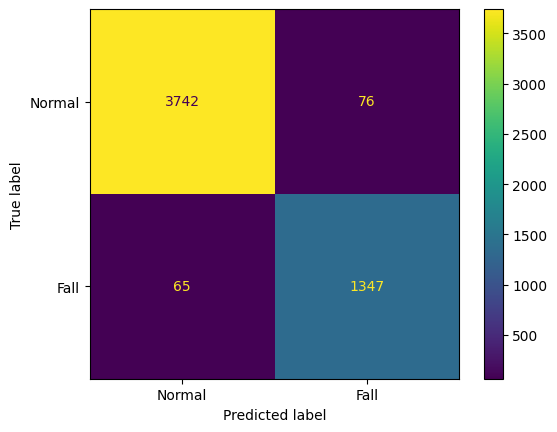

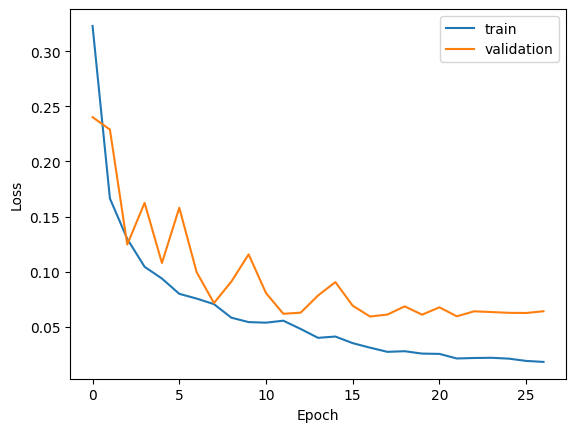

Kết quả: /content/results


In [10]:
# Ngưỡng chọn trên validation; test dùng sau khi cố định mô hình/ngưỡng.
model=tf.keras.models.load_model(OUT/'best_model.keras')
p_val=model.predict(X_val,verbose=0).ravel()
thresholds=np.linspace(.05,.95,181)
scores=[f1_score(y[val],p_val>=t,zero_division=0) for t in thresholds]
threshold=float(thresholds[np.argmax(scores)])
p_test=model.predict(X_test,verbose=0).ravel()
pred=(p_test>=threshold).astype(int)
report=classification_report(y[test],pred,labels=[0,1],target_names=['Normal','Fall'],output_dict=True,zero_division=0)
metrics={'threshold':threshold,'validation_f1_fall':float(max(scores)),
         'test_f1_fall':report['Fall']['f1-score'],'test_precision_fall':report['Fall']['precision'],
         'test_recall_fall':report['Fall']['recall'],'test_macro_f1':report['macro avg']['f1-score']}
print(json.dumps(metrics,indent=2))
print(classification_report(y[test],pred,labels=[0,1],target_names=['Normal','Fall'],zero_division=0))
print('Đạt test F1 Fall >= 0.90:',metrics['test_f1_fall']>=.90)
(OUT/'metrics.json').write_text(json.dumps({'metrics':metrics,'report':report},indent=2))
(OUT/'config.json').write_text(json.dumps({'seed':SEED,'feature_order':COLS,'original_fs':ORIGINAL_FS,
 'target_fs':TARGET_FS,'window':WINDOW,'step':STEP,'threshold':threshold,
 'label_policy':'Normal trials=0; fall trials: retain windows overlapping onset..impact, label 1'},indent=2))
pd.DataFrame({'path':sources[test],'subject':groups[test],'true':y[test],'probability':p_test,'prediction':pred}).to_csv(OUT/'test_predictions.csv',index=False)
ConfusionMatrixDisplay(confusion_matrix(y[test],pred,labels=[0,1]),display_labels=['Normal','Fall']).plot()
plt.savefig(OUT/'confusion_matrix.png',bbox_inches='tight'); plt.show()
plt.plot(history.history['loss'],label='train'); plt.plot(history.history['val_loss'],label='validation')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend()
plt.savefig(OUT/'loss.png',bbox_inches='tight'); plt.show()
print('Kết quả:',OUT)

In [11]:
from google.colab import files
import shutil
archive=shutil.make_archive('/content/fall_detection_results','zip',OUT)
files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>